# Calabar to Jamaica

Old Calabar, on the Cross River estuary in what is now south-eastern Nigeria, was one of the
main ports of the Bight of Biafra. This notebook follows the people embarked there who were
taken to Jamaica: how many, when, where they were landed, and how many died on the way.
New Calabar, in the Niger delta near Bonny, is a different port and is left out.

Numbers are the voyage database's imputed figures unless marked as recorded. They count
people on voyages known to the database, so they are lower bounds for the trade as a whole;
the Estimates model the trade by region, not by port.

Needs the full data: `uv run voyages fetch && uv run voyages build`.

In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import pandas as pd

import voyages
from voyages import Voyages

v = Voyages()
CALABAR = 60608  # Old Calabar. New Calabar (60622) is a different port.
calabar = v.query().embarked_from(CALABAR)
to_jamaica = v.transatlantic.embarked_from(CALABAR).disembarked_in("Jamaica")

## All voyages from Calabar

In [2]:
everything = calabar.summary()
everything

,dataset,voyages,embarked,voyages_with_embarked,disembarked,voyages_with_disembarked,first_year,last_year,drawable
0,transatlantic,955,269755,954,217728,945,1622,1843,886


In [3]:
destinations = calabar.by_region(
    "disembarkation", level="broad_region", measures=["voyages", "embarked", "disembarked"]
)
destinations

,disembarkation_broad_region,disembarkation_broad_region_name,voyages,embarked,disembarked
0,20000,Mainland North America,95,23011,18276
1,30000,Caribbean,679,197399,160148
2,40000,Spanish Mainland America,3,1079,880
3,50000,Brazil,74,20101,17704
4,60000,Africa,36,9479,7405
5,80000,Other,9,2668,2293
6,<NA>,NaN,59,16018,11022


In [4]:
caribbean = calabar.disembarked_in("Caribbean").by_region(
    "disembarkation", measures=["voyages", "disembarked"]
)
caribbean.sort_values("disembarked", ascending=False).head(8)

,disembarkation_region,disembarkation_region_name,voyages,disembarked
16,35100,Jamaica,185,46967
11,34200,Barbados,90,17929
23,36400,Saint-Domingue,61,13965
9,33800,Dominica,55,12479
6,33500,St. Kitts,48,10753
13,34400,Grenada,42,10123
5,33400,Antigua,32,7586
1,31300,Cuba,16,5991


## Calabar to Jamaica

In [5]:
jam = to_jamaica.summary()
jam

,dataset,voyages,embarked,voyages_with_embarked,disembarked,voyages_with_disembarked,first_year,last_year,drawable
0,transatlantic,185,57485,185,46967,185,1663,1807,185


In [6]:
by_decade = to_jamaica.by_decade(["voyages", "embarked", "disembarked"])
by_decade

,decade,voyages,embarked,disembarked
0,1660,3,926,643
1,1670,3,819,568
2,1680,11,2742,1808
3,1690,3,701,533
4,1700,5,1572,1073
5,1710,2,277,170
6,1720,6,1970,1532
7,1730,8,2230,1651
8,1740,21,6204,5205
9,1750,24,7083,5912


In [7]:
landings = to_jamaica.by(
    "disembarkation_place", "disembarkation_place_name", "disembarkation_precision",
    measures=["voyages", "disembarked"],
).sort_values("disembarked", ascending=False)  # fmt: skip
landings

,disembarkation_place,disembarkation_place_name,disembarkation_precision,voyages,disembarked
6,35114,Kingston,place,103,28524
7,35199,"Jamaica, port unspecified",representative,66,14443
3,35107,Montego Bay,place,9,2594
0,35102,Antonia,place,2,404
5,35110,Port Royal,place,1,290
2,35106,Martha Brae,place,2,288
1,35104,Falmouth (Jam.),place,1,216
4,35109,Port Maria,place,1,208


In [8]:
recorded = v.transatlantic.recorded_only().embarked_from(CALABAR).disembarked_in("Jamaica")
recorded_summary = recorded.summary()
recorded_summary

,dataset,voyages,captives_on_board_leaving_africa,voyages_with_captives_on_board_leaving_africa,captives_arrived_first_landing,voyages_with_captives_arrived_first_landing,first_year,last_year,drawable
0,transatlantic,172,8619,26,36023,138,1663,1807,172


## Calabar among the ports of the Bight of Biafra

In [9]:
biafra_ports = (
    v.transatlantic.embarked_from("Bight of Biafra")
    .disembarked_in("Jamaica")
    .by(
        "embarkation_place",
        "embarkation_place_name",
        "embarkation_precision",
        "embarkation_lat",
        "embarkation_lon",
        measures=["voyages", "disembarked"],
    )  # fmt: skip
    .sort_values("disembarked", ascending=False)
    .assign(share=lambda d: (d.disembarked / d.disembarked.sum() * 100).round(1))
)
biafra_ports[["embarkation_place_name", "voyages", "disembarked", "share"]]

,embarkation_place_name,voyages,disembarked,share
1,Bonny,414,137154,59.4
2,Calabar,185,46967,20.3
7,New Calabar,78,20506,8.9
9,"Bight of Biafra and Gulf of Guinea Islands, po...",70,19420,8.4
3,Cameroons,13,2924,1.3
6,Gabon,12,2321,1.0
8,São Tomé,2,743,0.3
4,Cameroons River,2,544,0.2
5,Cap Lopez,1,244,0.1
0,Bimbia,1,142,0.1


## Lives lost at sea

The difference between the imputed numbers embarked and disembarked is the imputed number of
people who died between the African coast and Jamaica. Compared here with the other main
ports of the Bight of Biafra and with all voyages to Jamaica.

In [10]:
def mortality(q):
    s = q.where("embarked_imputed IS NOT NULL AND disembarked_imputed IS NOT NULL").by(
        "dataset",
        measures=["voyages", "embarked", "disembarked"],
    )
    days = q.to_pandas(["middle_passage_days_imputed"]).middle_passage_days_imputed
    return pd.Series(
        {
            "voyages": int(s.voyages.sum()),
            "embarked": int(s.embarked.sum()),
            "died": int(s.embarked.sum() - s.disembarked.sum()),
            "died (%)": round((1 - s.disembarked.sum() / s.embarked.sum()) * 100, 1),
            "median days, Africa to landing": days.median(),
        }
    )


jamaica = v.transatlantic.disembarked_in("Jamaica")
deaths = pd.DataFrame(
    {
        "Calabar": mortality(to_jamaica),
        "Bonny": mortality(jamaica.embarked_from("Bonny")),
        "New Calabar": mortality(jamaica.embarked_from("New Calabar")),
        "All voyages to Jamaica": mortality(jamaica),
    }
).T.astype({"voyages": int, "embarked": int, "died": int})
deaths

,voyages,embarked,died,died (%),"median days, Africa to landing"
Calabar,185,57485,10518,18.3,68.5
Bonny,414,156590,19436,12.4,64.0
New Calabar,78,24485,3979,16.3,74.5
All voyages to Jamaica,3589,1087190,152613,14.0,62.0


Most of these numbers are imputed: where a voyage's losses were not recorded, the imputation
applies a rate for its group of voyages, which is why many early voyages show the same ratio
of landed to embarked. The voyages where both the number leaving Africa and the number
arriving were recorded give a check, on far fewer voyages:

In [11]:
jamaica_rec = v.transatlantic.recorded_only().disembarked_in("Jamaica")


def recorded_mortality(q):
    cols = ["captives_on_board_leaving_africa", "captives_arrived_first_landing"]
    both = q.where(" AND ".join(f"{c} IS NOT NULL" for c in cols)).to_pandas(cols)
    left, arrived = both.sum()
    return pd.Series(
        {
            "voyages": len(both),
            "left Africa": int(left),
            "arrived": int(arrived),
            "died (%)": round((1 - arrived / left) * 100, 1),
        }
    )


recorded_deaths = pd.DataFrame(
    {
        "Calabar": recorded_mortality(jamaica_rec.embarked_from(CALABAR)),
        "Bonny": recorded_mortality(jamaica_rec.embarked_from("Bonny")),
        "New Calabar": recorded_mortality(jamaica_rec.embarked_from("New Calabar")),
        "All voyages to Jamaica": recorded_mortality(jamaica_rec),
    }
).T.astype({"voyages": int, "left Africa": int, "arrived": int})
recorded_deaths

,voyages,left Africa,arrived,died (%)
Calabar,24,7964,6049,24.0
Bonny,58,22981,20718,9.8
New Calabar,9,2509,2403,4.2
All voyages to Jamaica,572,192132,172692,10.1


## Maps

Points are drawn where the data has them. A point marked as *representative* stands for a
record that names only a region ("Jamaica, port unspecified") and is drawn at its main port;
those are hollow. Voyages with no point at all are counted, not dropped.

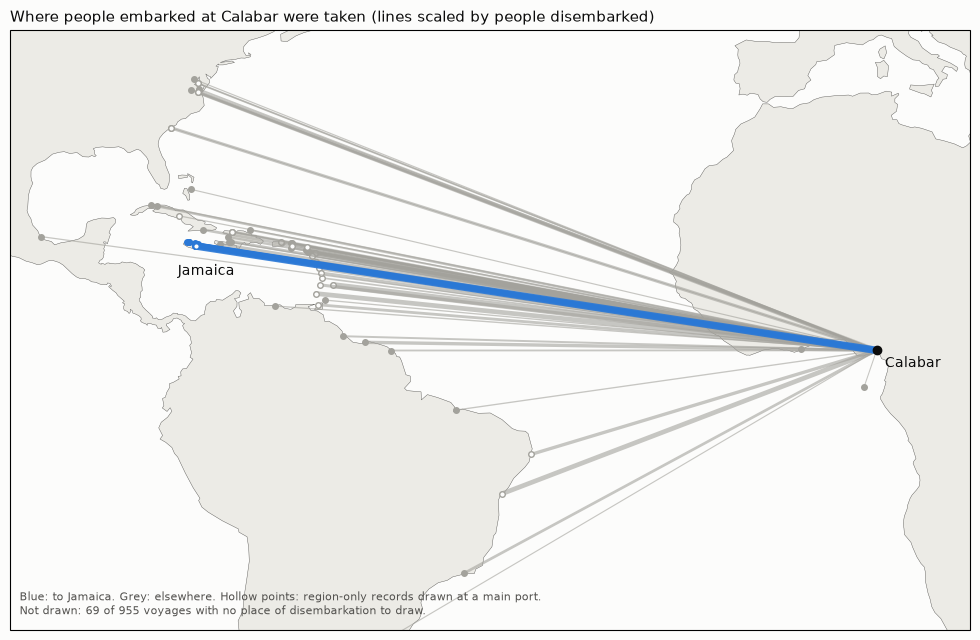

In [12]:
SURFACE, INK, MUTED, LAND, SEA = "#fcfcfb", "#0b0b0b", "#52514e", "#ecebe6", "#fcfcfb"
HIGHLIGHT, CONTEXT = "#2a78d6", "#a3a29c"
plt.rcParams.update({"figure.facecolor": SURFACE, "text.color": INK, "font.size": 10})

ends = calabar.endpoints()
routes = (
    ends[ends.drawable]
    .assign(
        people=lambda d: d.voyage_id.map(
            calabar.to_pandas(["voyage_id", "disembarked_imputed"])
            .set_index("voyage_id")
            .disembarked_imputed
        )
    )
    .groupby(
        [
            "disembarkation_map_code",
            "disembarkation_lat",
            "disembarkation_lon",
            "disembarkation_precision",
            "disembarkation_region",
        ],
        dropna=False,
    )  # fmt: skip
    .agg(voyages=("voyage_id", "size"), people=("people", "sum"))
    .reset_index()
)
routes["jamaica"] = routes.disembarkation_region == 35100
not_drawn = ends[~ends.drawable]
start = ends.loc[ends.embarkation_place == CALABAR, ["embarkation_lat", "embarkation_lon"]].iloc[0]


# Label positions (points) for places that sit close together: (dx, dy, alignment).
LABELS = {
    "Bonny": (14, -26, "left"),
    "New Calabar": (-12, 8, "right"),
    "Montego Bay": (-8, 8, "right"),
    "Falmouth (Jam.)": (0, 12, "center"),
    "Martha Brae": (6, -20, "left"),
    "Kingston": (14, -6, "left"),
    "Port Royal": (-8, -16, "right"),
}


def label(ax, name, people, lon, lat):
    dx, dy, ha = LABELS.get(name, (8, 4, "left"))
    ax.annotate(
        f"{name}\n{people:,}", (lon, lat), xytext=(dx, dy), textcoords="offset points",
        ha=ha, fontsize=8, transform=ccrs.PlateCarree(),
    )  # fmt: skip


def width(people, top):
    return 0.4 + 5 * (people / top) ** 0.5


fig = plt.figure(figsize=(11, 6.5))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-100, 20, -30, 45], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor=LAND, edgecolor="none")
ax.add_feature(cfeature.COASTLINE, linewidth=0.3, edgecolor=MUTED)
ax.set_facecolor(SEA)
top = routes.people.max()
for jam_route in (False, True):  # Jamaica on top
    for r in routes[routes.jamaica == jam_route].itertuples():
        ax.plot(
            [start.embarkation_lon, r.disembarkation_lon],
            [start.embarkation_lat, r.disembarkation_lat],
            transform=ccrs.PlateCarree(),
            color=HIGHLIGHT if r.jamaica else CONTEXT,
            linewidth=width(r.people, top),
            alpha=0.9 if r.jamaica else 0.6,
            solid_capstyle="round",
        )
        rep = r.disembarkation_precision != "place"
        ax.plot(
            r.disembarkation_lon, r.disembarkation_lat, "o", transform=ccrs.PlateCarree(),
            markersize=4, markerfacecolor=SURFACE if rep else (HIGHLIGHT if r.jamaica else CONTEXT),
            markeredgecolor=HIGHLIGHT if r.jamaica else CONTEXT, markeredgewidth=1,
        )  # fmt: skip
ax.plot(start.embarkation_lon, start.embarkation_lat, "o", color=INK, markersize=6,
        transform=ccrs.PlateCarree())  # fmt: skip
ax.annotate("Calabar", (start.embarkation_lon, start.embarkation_lat), xytext=(6, -12),
            textcoords="offset points", transform=ccrs.PlateCarree(), fontsize=10)  # fmt: skip
ax.annotate("Jamaica", (-77.3, 18.2), xytext=(-10, -22), textcoords="offset points",
            color=INK, fontsize=10, transform=ccrs.PlateCarree())  # fmt: skip
ax.set_title(
    "Where people embarked at Calabar were taken (lines scaled by people disembarked)",
    loc="left", fontsize=11,
)  # fmt: skip
ax.text(
    0.01, 0.02,
    f"Blue: to Jamaica. Grey: elsewhere. Hollow points: region-only records drawn at a main port.\n"
    f"Not drawn: {len(not_drawn)} of {len(ends)} voyages with no place of disembarkation to draw.",
    transform=ax.transAxes, fontsize=8, color=MUTED, va="bottom",
)  # fmt: skip
fig.tight_layout()
fig.savefig("figures/02_calabar_routes.png", dpi=150)

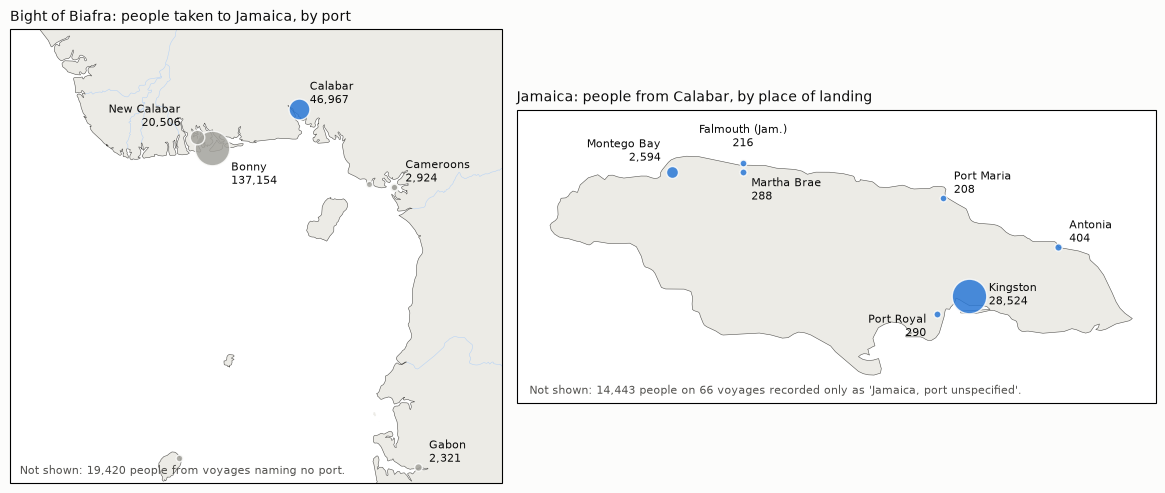

In [13]:
fig, (ax_af, ax_jm) = plt.subplots(
    1, 2, figsize=(12, 5), subplot_kw={"projection": ccrs.PlateCarree()},
    gridspec_kw={"width_ratios": [1, 1.3]},
)  # fmt: skip
for ax in (ax_af, ax_jm):
    ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor=LAND, edgecolor="none")
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.4, edgecolor=MUTED)
    ax.add_feature(cfeature.RIVERS.with_scale("10m"), linewidth=0.4, edgecolor="#b7d3f6")

# Bight of Biafra: ports by people taken to Jamaica.
ax_af.set_extent([4.5, 11, 0, 6], crs=ccrs.PlateCarree())
ports = biafra_ports[biafra_ports.embarkation_precision == "place"]
size_top = ports.disembarked.max()
for p in ports.itertuples():
    is_cal = p.embarkation_place == CALABAR
    ax_af.scatter(
        p.embarkation_lon, p.embarkation_lat, s=20 + 600 * p.disembarked / size_top,
        color=HIGHLIGHT if is_cal else CONTEXT, alpha=0.85, edgecolor=SURFACE, linewidth=1,
        transform=ccrs.PlateCarree(), zorder=3,
    )  # fmt: skip
    if p.disembarked > 2000:
        label(ax_af, p.embarkation_place_name, p.disembarked, p.embarkation_lon, p.embarkation_lat)
unspecified = biafra_ports[biafra_ports.embarkation_precision != "place"].disembarked.sum()
ax_af.set_title("Bight of Biafra: people taken to Jamaica, by port", loc="left", fontsize=10)
ax_af.text(
    0.02, 0.02, f"Not shown: {unspecified:,} people from voyages naming no port.",
    transform=ax_af.transAxes, fontsize=8, color=MUTED,
)  # fmt: skip

# Jamaica: where people from Calabar were landed.
ax_jm.set_extent([-78.5, -76.1, 17.6, 18.7], crs=ccrs.PlateCarree())
named = landings[landings.disembarkation_precision == "place"].merge(
    v.sql("SELECT code AS disembarkation_place, lat, lon FROM places").to_pandas()
)
for p in named.itertuples():
    ax_jm.scatter(
        p.lon, p.lat, s=20 + 600 * p.disembarked / named.disembarked.max(), color=HIGHLIGHT,
        alpha=0.85, edgecolor=SURFACE, linewidth=1, transform=ccrs.PlateCarree(), zorder=3,
    )  # fmt: skip
    label(ax_jm, p.disembarkation_place_name, p.disembarked, p.lon, p.lat)
port_unknown = landings[landings.disembarkation_precision != "place"]
ax_jm.set_title("Jamaica: people from Calabar, by place of landing", loc="left", fontsize=10)
ax_jm.text(
    0.02, 0.03,
    f"Not shown: {port_unknown.disembarked.sum():,} people on {port_unknown.voyages.sum()} voyages "
    "recorded only as 'Jamaica, port unspecified'.",
    transform=ax_jm.transAxes, fontsize=8, color=MUTED,
)  # fmt: skip
fig.tight_layout()
fig.savefig("figures/02_calabar_ports.png", dpi=150)

## The voyages

Every voyage in the database that carried captives from Calabar to Jamaica, with its imputed
numbers. The full list is the source for everything above.

In [14]:
voyage_list = to_jamaica.to_pandas(
    ["voyage_id", "ship_name", "year_arrived_imputed", "flag_imputed_name",
     "embarked_imputed", "disembarked_imputed", "disembarkation_place_name"],
).merge(
    v.sql("SELECT voyage_id, name AS captain FROM voyage_enslavers "
          "WHERE role = 'captain' AND seq = 1").to_pandas(),
    how="left",
).sort_values("year_arrived_imputed")  # fmt: skip
voyage_list.head(10)

,voyage_id,ship_name,year_arrived_imputed,flag_imputed_name,embarked_imputed,disembarked_imputed,disembarkation_place_name,captain
0,9554,Hope,1663,Great Britain,229,159,"Jamaica, port unspecified","Pepperell, Nicholas"
77,21244,Elizabeth,1664,Great Britain,223,155,"Jamaica, port unspecified","Lumley, Richard"
1,9620,Blackamore,1665,Great Britain,474,329,"Jamaica, port unspecified",Hayward
73,20898,Portmorant Merchant,1674,Great Britain,251,174,"Jamaica, port unspecified","Taylor, James"
10,9974,America,1676,Great Britain,349,242,"Jamaica, port unspecified","Ellyard, Samuel"
11,9987,Vine,1678,Great Britain,219,152,"Jamaica, port unspecified","Coleman, John"
9,9957,Vine,1680,Great Britain,401,278,"Jamaica, port unspecified","Branfield, Andrew"
8,9898,Arthur,1682,Great Britain,164,114,"Jamaica, port unspecified","Penny, George"
15,15244,Owner's Goodwill,1683,Great Britain,197,137,"Jamaica, port unspecified",Wall
6,9871,Return,1684,Great Britain,330,134,"Jamaica, port unspecified","Davies, William"


In [15]:
voyage_list.tail(10)

,voyage_id,ship_name,year_arrived_imputed,flag_imputed_name,embarked_imputed,disembarked_imputed,disembarkation_place_name,captain
94,80298,Anna Bella,1800,Great Britain,62,48,Kingston,"Gardner, William"
108,81532,Friendship,1800,Great Britain,238,218,Kingston,"Elliott, Adam"
139,83837,Trelawney,1801,Great Britain,354,318,Kingston,"Smith, Thomas"
100,80773,Ceres,1804,Great Britain,334,300,Kingston,"Elliott, Adam"
98,80407,Bacchus,1805,Great Britain,308,277,Kingston,"Hughes, Richard"
96,80403,Aurora,1805,Great Britain,244,219,Kingston,"Chamley, Thomas (Jr)"
127,82941,Nile,1806,Great Britain,304,273,Kingston,"Anderson, John"
141,84043,William,1807,Great Britain,219,201,Kingston,"Williams, Joseph"
125,82802,Montezuma,1807,Great Britain,320,288,Kingston,"Webster, Thomas"
115,81644,Governor Dowdeswell,1807,Great Britain,274,246,Kingston,"Young, John"


In [16]:
# The figures quoted below, checked against the tables above.
e = everything.iloc[0]
assert (e.voyages, e.embarked, e.disembarked, e.first_year, e.last_year) == (
    955, 269_755, 217_728, 1622, 1843,
)  # fmt: skip
carib = destinations.set_index("disembarkation_broad_region_name").loc["Caribbean"]
assert (carib.voyages, carib.disembarked) == (679, 160_148)
top = caribbean.sort_values("disembarked", ascending=False)
assert top.disembarkation_region_name.tolist()[:2] == ["Jamaica", "Barbados"]
j = jam.iloc[0]
assert (j.voyages, j.embarked, j.disembarked, j.first_year, j.last_year) == (
    185, 57_485, 46_967, 1663, 1807,
)  # fmt: skip
shares = biafra_ports.set_index("embarkation_place_name").share
assert (shares["Bonny"], shares["Calabar"]) == (59.4, 20.3)
land = landings.set_index("disembarkation_place_name")
assert (land.loc["Kingston", "voyages"], land.loc["Kingston", "disembarked"]) == (103, 28_524)
unspec = land.loc["Jamaica, port unspecified"]
assert (unspec.voyages, unspec.disembarked) == (66, 14_443)
peak = by_decade.set_index("decade").loc[1790]
assert by_decade.disembarked.idxmax() == by_decade.decade.tolist().index(1790)
assert (peak.voyages, peak.disembarked) == (31, 8_853)
assert (voyage_list.year_arrived_imputed == 1807).sum() == 3
assert (deaths.loc["Calabar", "died"], deaths.loc["Calabar", "died (%)"]) == (10_518, 18.3)
assert deaths.loc["All voyages to Jamaica", "died (%)"] == 14.0
assert deaths.loc["Bonny", "died (%)"] == 12.4
rd = recorded_deaths
assert (rd.loc["Calabar", "voyages"], rd.loc["Calabar", "died (%)"]) == (24, 24.0)
assert (rd.loc["Bonny", "died (%)"], rd.loc["All voyages to Jamaica", "died (%)"]) == (9.8, 10.1)
r = recorded_summary.iloc[0]
assert (r.voyages_with_captives_arrived_first_landing, r.captives_arrived_first_landing) == (
    138, 36_023,
)  # fmt: skip

## Reading the results

- The database holds 955 voyages that embarked captives at Calabar between 1622 and 1843:
  269,755 people embarked and 217,728 landed. Most (679 voyages, 160,148 people landed) went
  to the Caribbean.
- Jamaica was the largest single destination: 185 voyages between 1663 and 1807 landed 46,967
  of 57,485 people embarked. Barbados came next.
- Calabar supplied a fifth (20.3 per cent) of the people brought to Jamaica from the Bight of
  Biafra; Bonny supplied most of the rest (59.4 per cent).
- Kingston received the most: 103 voyages, 28,524 people. Another 66 voyages, 14,443 people,
  are recorded only as landing in Jamaica, place not named.
- The trade grew from the 1740s and peaked in the 1790s (31 voyages, 8,853 people landed). The
  last three voyages arrived in 1807, the year Britain abolished its slave trade.
- About 10,518 people (18.3 per cent) died between Calabar and Jamaica by the imputed figures,
  against 14.0 per cent for all voyages to Jamaica and 12.4 per cent from Bonny. Most of those
  figures apply group rates; the 24 voyages with both numbers recorded lost 24.0 per cent,
  against 9.8 per cent from Bonny and 10.1 per cent for all voyages to Jamaica with both
  numbers. 24 voyages is a small sample, but it points the same way.
- For 138 of the 185 voyages the number of people arriving was recorded: 36,023 in all.

## Source and licence

Imputed variables are licensed CC BY-NC 4.0 by SlaveVoyages; the recorded data is public
domain. Coastlines: Natural Earth (public domain). Place coordinates: see docs/DATA.md.

In [17]:
print(voyages.citation())

SlaveVoyages, Trans-Atlantic Slave Trade Database, https://www.slavevoyages.org (accessed October 19, 2026).
